In [1]:
from google.colab import files

uploaded = files.upload()

Saving DHS_Daily_Report_20260929.csv to DHS_Daily_Report_20260929.csv


In [2]:
!ls

DHS_Daily_Report_20260929.csv  sample_data


In [3]:
import pandas as pd



In [5]:
df = pd.read_csv('DHS_Daily_Report_20260929.csv')

In [6]:
df.head()
df.shape

(2038, 13)

In [7]:
df.info()
df.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2038 entries, 0 to 2037
Data columns (total 13 columns):
 #   Column                                                   Non-Null Count  Dtype 
---  ------                                                   --------------  ----- 
 0   Date of Census                                           2038 non-null   object
 1   Total Adults in Shelter                                  2038 non-null   int64 
 2   Total Children in Shelter                                2038 non-null   int64 
 3   Total Individuals in Shelter                             2038 non-null   int64 
 4   Single Adult Men in Shelter                              2038 non-null   int64 
 5   Single Adult Women in Shelter                            2038 non-null   int64 
 6   Total Single Adults in Shelter                           2038 non-null   int64 
 7   Families with Children in Shelter                        2038 non-null   int64 
 8   Adults in Families with Children in Sh

,0
Date of Census,0
Total Adults in Shelter,0
Total Children in Shelter,0
Total Individuals in Shelter,0
Single Adult Men in Shelter,0
Single Adult Women in Shelter,0
Total Single Adults in Shelter,0
Families with Children in Shelter,0
Adults in Families with Children in Shelter,0
Children in Families with Children in Shelter,0


In [8]:
df['Date of Census'] = pd.to_datetime(df['Date of Census'])
df = df.sort_values('Date of Census')

In [9]:
df['Year'] = df['Date of Census'].dt.year

In [10]:
df.info()
df['Date of Census'].min(), df['Date of Census'].max()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2038 entries, 0 to 2037
Data columns (total 14 columns):
 #   Column                                                   Non-Null Count  Dtype         
---  ------                                                   --------------  -----         
 0   Date of Census                                           2038 non-null   datetime64[ns]
 1   Total Adults in Shelter                                  2038 non-null   int64         
 2   Total Children in Shelter                                2038 non-null   int64         
 3   Total Individuals in Shelter                             2038 non-null   int64         
 4   Single Adult Men in Shelter                              2038 non-null   int64         
 5   Single Adult Women in Shelter                            2038 non-null   int64         
 6   Total Single Adults in Shelter                           2038 non-null   int64         
 7   Families with Children in Shelter                  

(Timestamp('2021-03-01 00:00:00'), Timestamp('2026-09-28 00:00:00'))

In [11]:
df.columns = df.columns.str.strip()
df.columns.tolist()

['Date of Census',
 'Total Adults in Shelter',
 'Total Children in Shelter',
 'Total Individuals in Shelter',
 'Single Adult Men in Shelter',
 'Single Adult Women in Shelter',
 'Total Single Adults in Shelter',
 'Families with Children in Shelter',
 'Adults in Families with Children in Shelter',
 'Children in Families with Children in Shelter',
 'Total Individuals in Families with Children in Shelter',
 'Adult Families in Shelter',
 'Individuals in Adult Families in Shelter',
 'Year']

Cleaned the column names. Reason: space at the end

In [12]:
df[['Total Individuals in Shelter',
    'Total Single Adults in Shelter',
    'Total Individuals in Families with Children in Shelter']].describe().round(0)

,Total Individuals in Shelter,Total Single Adults in Shelter,Total Individuals in Families with Children in Shelter
count,2038.0,2038.0,2038.0
mean,72856.0,20651.0,47796.0
std,17052.0,2927.0,14284.0
min,44586.0,15985.0,25039.0
25%,51126.0,18046.0,29598.0
50%,83324.0,20615.0,53448.0
75%,86106.0,22448.0,59606.0
max,89558.0,26903.0,64112.0


This shows the count, average, minimum, maximum, and quartiles for the three main shelter groups. It gives a quick picture of how many people are in shelters on a typical day.

In [13]:
yearly = df.groupby('Year')[['Total Individuals in Shelter',
                             'Total Single Adults in Shelter',
                             'Total Individuals in Families with Children in Shelter']].mean().round(0)

yearly

,Total Individuals in Shelter,Total Single Adults in Shelter,Total Individuals in Families with Children in Shelter
Year,,,
2021,47077.0,17031.0,26540.0
2022,51857.0,17546.0,30755.0
2023,80049.0,21235.0,53208.0
2024,87105.0,20502.0,62401.0
2025,85651.0,22736.0,58301.0
2026,84079.0,25529.0,53588.0


This groups the data by year and calculates the average shelter population for each year. It shows whether the numbers have grown and by how much.

In [14]:
first = df.iloc[0]
last = df.iloc[-1]

print("First day:", first['Date of Census'].date())
print("Total individuals:", first['Total Individuals in Shelter'])
print()
print("Last day:", last['Date of Census'].date())
print("Total individuals:", last['Total Individuals in Shelter'])

First day: 2021-03-01
Total individuals: 51941

Last day: 2026-09-28
Total individuals: 84374


This compares the number of people in shelters on the first day of data vs. the last day, so we can see the total change over the entire period.

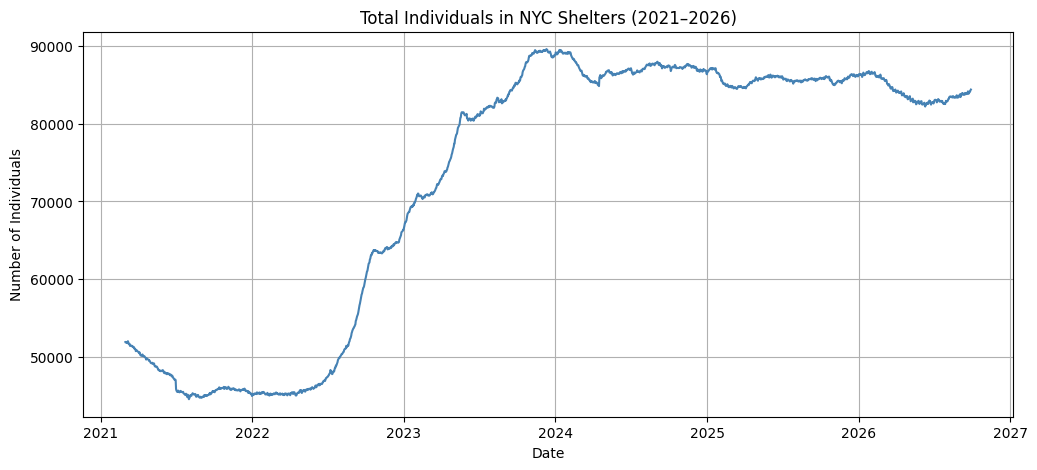

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(df['Date of Census'], df['Total Individuals in Shelter'], color='steelblue')
plt.title('Total Individuals in NYC Shelters (2021–2026)')
plt.xlabel('Date')
plt.ylabel('Number of Individuals')
plt.grid(True)
plt.show()

This line chart shows the total number of people in NYC shelters every day from March 2021 to September 2026. The upward slope shows a clear growth trend. The steepest rise happens between 2022 and 2023.

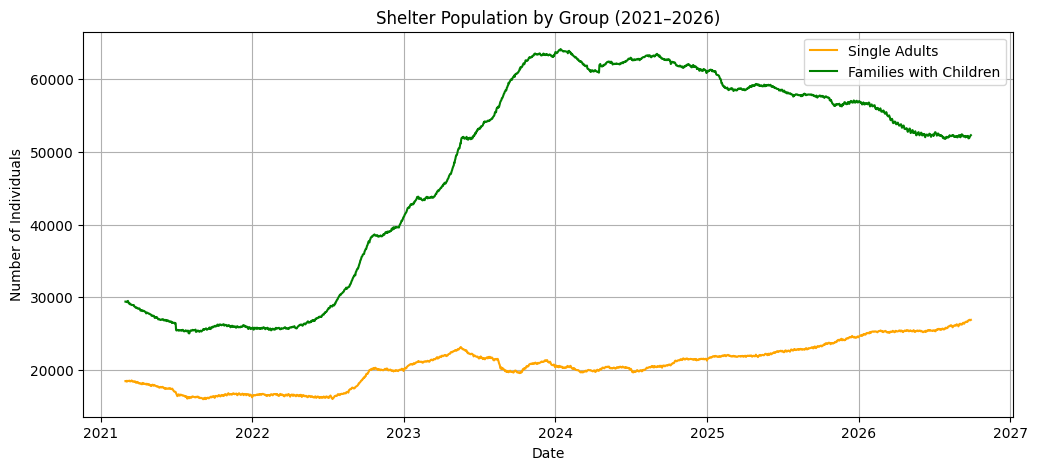

In [16]:
plt.figure(figsize=(12, 5))
plt.plot(df['Date of Census'], df['Total Single Adults in Shelter'],
         label='Single Adults', color='orange')
plt.plot(df['Date of Census'], df['Total Individuals in Families with Children in Shelter'],
         label='Families with Children', color='green')
plt.title('Shelter Population by Group (2021–2026)')
plt.xlabel('Date')
plt.ylabel('Number of Individuals')
plt.legend()
plt.grid(True)
plt.show()

This chart compares single adults and families with children. It shows that families with children grew much faster between 2022 and 2024, while single adults grew more steadily. By 2024, families with children were the largest group in the shelter system.

In [17]:
df[['Date of Census', 'Single Adult Men in Shelter', 'Single Adult Women in Shelter']].describe().round(0)

,Date of Census,Single Adult Men in Shelter,Single Adult Women in Shelter
count,2038,2038.0,2038.0
mean,2023-12-14 12:00:00,15445.0,5207.0
min,2021-03-01 00:00:00,11971.0,3801.0
25%,2022-07-23 06:00:00,13688.0,4346.0
50%,2023-12-14 12:00:00,15744.0,4985.0
75%,2025-05-06 18:00:00,16792.0,5770.0
max,2026-09-28 00:00:00,19311.0,7611.0
std,NaN,1983.0,1081.0


Single adult men consistently make up about 75% of single adults in NYC shelters. Both men and women increased over the period, but women nearly doubled, showing faster relative growth.

In [18]:
df['Pct Men'] = (df['Single Adult Men in Shelter'] / df['Total Single Adults in Shelter']) * 100
df['Pct Women'] = (df['Single Adult Women in Shelter'] / df['Total Single Adults in Shelter']) * 100

df[['Date of Census', 'Pct Men', 'Pct Women']].describe().round(1)

,Date of Census,Pct Men,Pct Women
count,2038,2038.0,2038.0
mean,2023-12-14 12:00:00,74.9,25.1
min,2021-03-01 00:00:00,71.0,20.0
25%,2022-07-23 06:00:00,73.8,24.2
50%,2023-12-14 12:00:00,75.1,24.9
75%,2025-05-06 18:00:00,75.8,26.2
max,2026-09-28 00:00:00,80.0,29.0
std,NaN,2.2,2.2


When I analyzed the gender split among single adults, I found a striking pattern: men consistently make up about 75% of single adults in NYC shelters, while women make up about 25%. What makes this finding notable is how stable it is — the standard deviation is only 2.2 percentage points, meaning the ratio barely changes from day to day, month to month, or year to year. Even though the total number of single adults grew significantly, the gender ratio stayed almost constant.

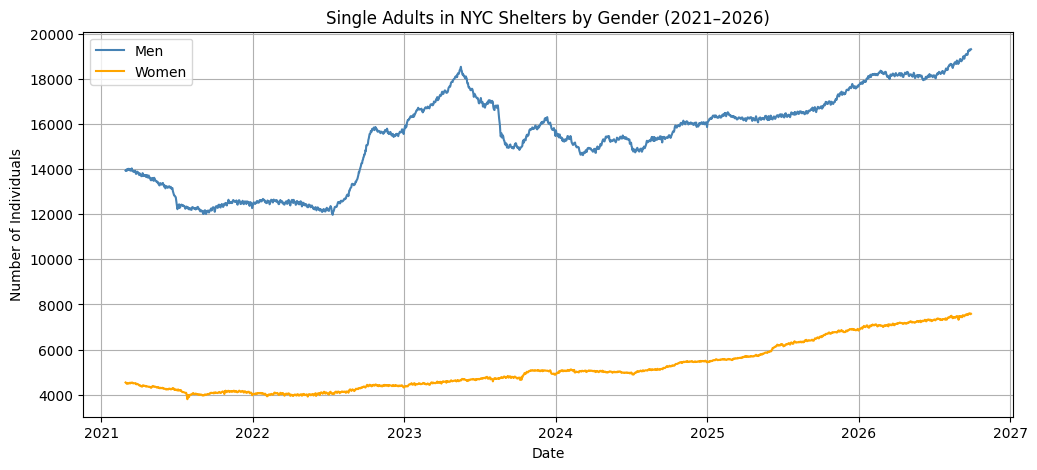

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(df['Date of Census'], df['Single Adult Men in Shelter'],
         label='Men', color='steelblue')
plt.plot(df['Date of Census'], df['Single Adult Women in Shelter'],
         label='Women', color='orange')
plt.title('Single Adults in NYC Shelters by Gender (2021–2026)')
plt.xlabel('Date')
plt.ylabel('Number of Individuals')
plt.legend()
plt.grid(True)
plt.show()

This chart compares the number of single adult men and women in shelters over time. Men consistently outnumber women by a large margin, and both groups grew steadily over the period.

CONCLUSION:
NYC's shelter population grew 62% between March 2021 and September 2026, driven mostly by families with children. Among single adults, men consistently made up about 75% of the population, and this ratio remained remarkably stable throughout the period. These trends show that demand for shelter services has grown dramatically and remains at high levels, putting the system under sustained pressure.